# Data Analysis for Optimization of the Comminution Stage in a Copper Ore Processing Plant

### Applying Data Analysis to Improve Efficiency and Process Control in comminution Operations

## Objective  
Apply data analysis techniques to study the behavior of the comminution process (crushing and grinding) based on operational and mineralogical variables (using a dataset artificially generated by AI), with the goal of identifying opportunities for improvement in energy efficiency, particle size distribution, and throughput.

## Expected Outcomes  
1. Demonstrate technical skills in using Python for data analysis.  
2. Provide operational recommendations to improve efficiency.  
3. Identify patterns in process behavior.  
4. Potential development of a simple predictive model to support decision-making.

## 1. DATA OVERVIEW


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sb
import numpy as np

The data used in the following analysis was artificially generated to simulate real operating conditions in a copper ore comminution plant.

In [3]:
# Data Loading
data = pd.read_csv("dataset_conminucion_simulado.csv")

In [4]:
# Column validation
print(data.columns)

# Check for spaces or line breaks in column names
for col in data.columns:
    print(f"-{col}-") 

Index(['Fecha', 'Turno', 'Tipo_Mineral', 'Dureza_BWI', 'TPH',
       'Consumo_Energia_kWh', 'P80_Entrada_micrones', 'P80_Salida_micrones',
       'Porcentaje_Solidos', 'RPM_Molino', 'Horas_Operacion', 'kWh_por_Ton',
       'Reduccion_P80'],
      dtype='object')
-Fecha-
-Turno-
-Tipo_Mineral-
-Dureza_BWI-
-TPH-
-Consumo_Energia_kWh-
-P80_Entrada_micrones-
-P80_Salida_micrones-
-Porcentaje_Solidos-
-RPM_Molino-
-Horas_Operacion-
-kWh_por_Ton-
-Reduccion_P80-


In [5]:
# Data Overview
data.head(10)

,Fecha,Turno,Tipo_Mineral,Dureza_BWI,TPH,Consumo_Energia_kWh,P80_Entrada_micrones,P80_Salida_micrones,Porcentaje_Solidos,RPM_Molino,Horas_Operacion,kWh_por_Ton,Reduccion_P80
0,2024-01-01,B,Supérgeno,12.2,1308.0,1371.4,9245.0,292.0,66.4,12.5,20.5,0.051,8953.0
1,2024-01-02,A,Hipógeno,13.2,1648.0,1220.0,12463.0,221.0,70.0,11.6,20.7,0.036,12242.0
2,2024-01-03,B,Hipógeno,12.6,1421.0,1195.0,12870.0,209.0,68.5,12.8,21.4,0.039,12661.0
3,2024-01-04,A,Supérgeno,11.8,1434.0,1309.8,7415.0,225.0,68.9,10.1,22.2,0.041,7190.0
4,2024-01-05,B,Mixto,10.6,1400.0,1106.5,12714.0,224.0,67.0,12.1,22.4,0.035,12490.0
5,2024-01-06,A,Supérgeno,12.2,1452.0,1155.6,12677.0,119.0,64.2,11.1,21.9,0.036,12558.0
6,2024-01-07,B,Mixto,14.2,1556.0,1032.0,10039.0,294.0,56.9,11.4,23.0,0.029,9745.0
7,2024-01-08,C,Supérgeno,15.6,1427.0,1074.6,11865.0,103.0,64.3,12.4,22.9,0.033,11762.0
8,2024-01-09,C,Hipógeno,12.6,1527.0,1392.3,12066.0,257.0,55.8,11.2,21.7,0.042,11809.0
9,2024-01-10,A,Supérgeno,13.5,1713.0,1269.2,9495.0,203.0,68.3,11.8,20.5,0.036,9292.0


In [6]:
# Check for duplicate entries by date
data['Fecha'].duplicated().sum()

0

In [7]:
# General info for each column
data.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Fecha                 1000 non-null   object 
 1   Turno                 1000 non-null   object 
 2   Tipo_Mineral          1000 non-null   object 
 3   Dureza_BWI            970 non-null    float64
 4   TPH                   970 non-null    float64
 5   Consumo_Energia_kWh   970 non-null    float64
 6   P80_Entrada_micrones  1000 non-null   float64
 7   P80_Salida_micrones   1000 non-null   float64
 8   Porcentaje_Solidos    1000 non-null   float64
 9   RPM_Molino            970 non-null    float64
 10  Horas_Operacion       1000 non-null   float64
 11  kWh_por_Ton           1000 non-null   float64
 12  Reduccion_P80         1000 non-null   float64
dtypes: float64(10), object(3)
memory usage: 101.7+ KB


In [8]:
# Null cells per column
data.isnull().sum()

Fecha                    0
Turno                    0
Tipo_Mineral             0
Dureza_BWI              30
TPH                     30
Consumo_Energia_kWh     30
P80_Entrada_micrones     0
P80_Salida_micrones      0
Porcentaje_Solidos       0
RPM_Molino              30
Horas_Operacion          0
kWh_por_Ton              0
Reduccion_P80            0
dtype: int64

Text(0.5, 1.0, 'Null Value Map')

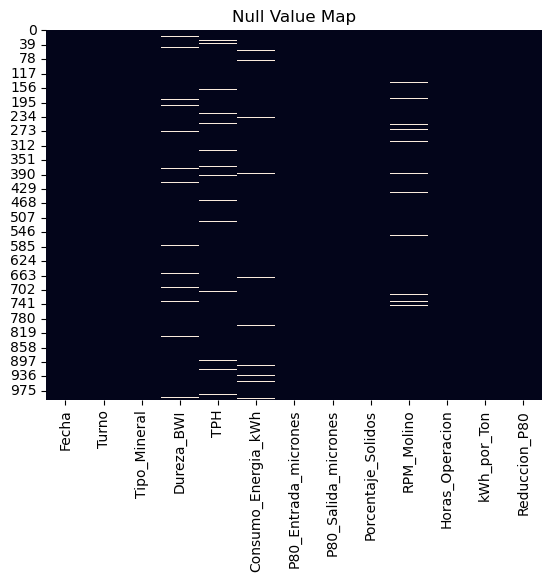

In [29]:
# Visual representation to locate null values in the DataFrame
sb.heatmap(data.isnull(), cbar=False)
plt.title("Null Value Map")

In [10]:
# Descriptive statistics
data.describe()

,Dureza_BWI,TPH,Consumo_Energia_kWh,P80_Entrada_micrones,P80_Salida_micrones,Porcentaje_Solidos,RPM_Molino,Horas_Operacion,kWh_por_Ton,Reduccion_P80
count,970.000000,970.000000,970.000000,1000.000000,1000.000000,1000.000000,970.000000,1000.000000,1000.000000,1000.000000
mean,12.069485,1502.530928,1196.669278,9989.306000,208.531476,61.936830,11.970103,21.987500,0.036671,9789.932000
std,1.945028,153.659097,100.887934,2003.241298,105.333759,6.632785,1.488543,1.135854,0.005325,2004.817751
min,5.900000,1072.000000,908.800000,1892.000000,48.000000,0.728781,7.300000,20.000000,0.022000,1666.000000
25%,10.700000,1399.250000,1127.500000,8621.000000,164.000000,58.500000,10.900000,21.000000,0.033000,8408.750000
50%,12.100000,1503.000000,1195.450000,10104.500000,200.500000,62.400000,11.900000,22.000000,0.036000,9891.000000
75%,13.400000,1613.750000,1263.650000,11355.750000,235.000000,66.200000,13.000000,22.900000,0.040000,11180.500000
max,19.200000,2033.000000,1507.600000,15062.000000,1391.770863,70.000000,16.700000,24.000000,0.055000,14819.000000


Observations based on descriptive statistics:

- The P80 output ranges from 48 to 1391 microns, suggesting the possible presence of outliers.  
- The minimum solids percentage is 0.7%, which also indicates potential outliers.  
- Hardness and P80 input values appear to fall within normal ranges.  
- Mill RPM ranges from 7.3 to 16.7. Since the average is approximately 12, there may be outliers present.


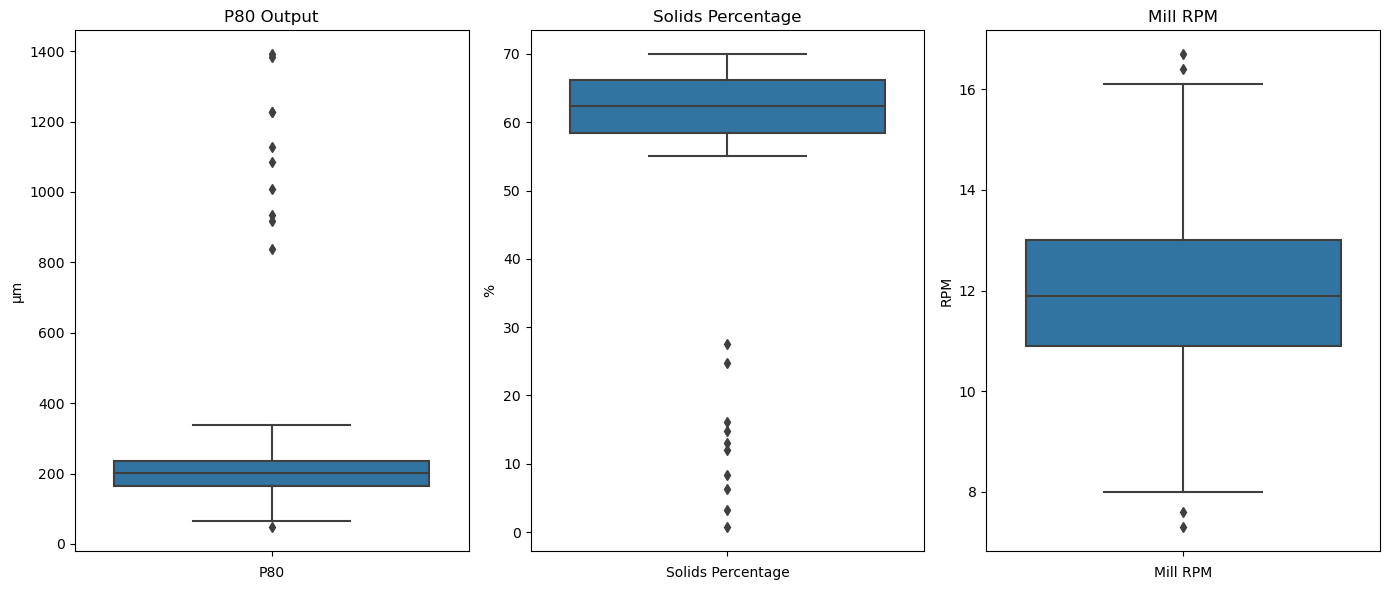

In [30]:
# Confirm the presence of outliers using boxplots

fig, axes = plt.subplots(1, 3, figsize=(14,6))

# Boxplot for P80 Output
sb.boxplot(data=data, y='P80_Salida_micrones', ax=axes[0])
axes[0].set_title('P80 Output')
axes[0].set_xlabel('P80')
axes[0].set_ylabel('μm')

# Boxplot for Solids Percentage
sb.boxplot(data=data, y='Porcentaje_Solidos', ax=axes[1])
axes[1].set_title('Solids Percentage')
axes[1].set_xlabel('Solids Percentage')
axes[1].set_ylabel('%')

# Boxplot for Mill RPM
sb.boxplot(data=data, y='RPM_Molino', ax=axes[2])
axes[2].set_title('Mill RPM')
axes[2].set_xlabel('Mill RPM')
axes[2].set_ylabel('RPM')

plt.tight_layout()

We observe several points above the upper whisker in all three variables, indicating the presence of potential outliers.


In [31]:
# Count the number of outliers for P80 and Solids Percentage

outlier_P80 = (data['P80_Salida_micrones'] > 400).sum()
outlier_Porc_Sol = (data['Porcentaje_Solidos'] <= 30).sum()

print(f'Outliers with P80 above 400 μm: {outlier_P80}')
print(f'Outliers with Solids Percentage below 30%: {outlier_Porc_Sol}')

Outliers with P80 above 400 μm: 10
Outliers with Solids Percentage below 30%: 10


In [32]:
# Check how many Mill RPM events are recorded above 12, 13, 14, 15, and 16 RPM

RPM_12 = (data['RPM_Molino'] > 12).sum()
RPM_13 = (data['RPM_Molino'] > 13).sum()
RPM_14 = (data['RPM_Molino'] > 14).sum()
RPM_15 = (data['RPM_Molino'] > 15).sum()
RPM_16 = (data['RPM_Molino'] > 16).sum()

print(f'RPM greater then 12:{RPM_12}')
print(f'RPM greater then 13:{RPM_13}')
print(f'RPM greater then 14:{RPM_14}')
print(f'RPM greater then 15:{RPM_15}')
print(f'RPM greater then 16:{RPM_16}')

RPM greater then 12:458
RPM greater then 13:230
RPM greater then 14:87
RPM greater then 15:22
RPM greater then 16:3


In [14]:
# We will only review the data associated with RPM > 16 to check for anomalies. 
# This will help decide whether to remove those data points or not.

data[data['RPM_Molino'] > 16]

,Fecha,Turno,Tipo_Mineral,Dureza_BWI,TPH,Consumo_Energia_kWh,P80_Entrada_micrones,P80_Salida_micrones,Porcentaje_Solidos,RPM_Molino,Horas_Operacion,kWh_por_Ton,Reduccion_P80
271,2024-09-28,C,Hipógeno,10.0,1648.0,1222.3,11531.0,93.0,58.6,16.7,23.1,0.032,11438.0
638,2025-09-30,C,Supérgeno,13.5,1790.0,1234.3,10560.0,137.0,64.6,16.1,22.1,0.031,10423.0
971,2026-08-29,C,Mixto,12.5,1235.0,1173.3,14083.0,232.0,55.3,16.4,21.4,0.044,13851.0


A visual inspection shows potential outliers in all three variables. Let’s analyze each one:

1. For P80 Output, there are 10 values above 800 microns in particle size. These values are far outside the typical operating range, which is generally between 100 and 300 microns. Since the dataset is artificially generated and we cannot investigate the cause of these anomalies, these data points will be removed. They represent approximately 1% of the dataset. The outlier below the statistical minimum will be retained, as it appears to be within an acceptable range.

2. The outliers found in the Solids Percentage are significantly below the minimum operating threshold typically observed in real plants. For the same reason mentioned above, these rows will also be removed.

3. Four statistical outliers are observed in Mill RPM. The typical RPM range for a SAG mill is between 6 and 12 RPM. Therefore, the two outliers above the statistical maximum are considered to be outside the acceptable range. Upon further inspection, three events were found with RPM greater than 16. The only notable observation is that all three occurred under Shift C supervision. However, the rest of the variables for those events are within acceptable ranges. Therefore, these data points will be retained for the analysis stage.


In [15]:
data[['Turno', 'Tipo_Mineral']].apply(pd.Series.value_counts)

,Turno,Tipo_Mineral
A,322.0,NaN
B,351.0,NaN
C,327.0,NaN
Desconocido,NaN,20.0
Hipógeno,NaN,372.0
Mixto,NaN,191.0
Supérgeno,NaN,417.0


### FINAL Observations from the Preliminary Analysis:

1. There are 4 columns with a total of 30 null values: **"Dureza_BWI", "TPH", "Consumo_Energia_kWh", "RPM_Molino"**.
2. The **Mineral Type** column contains 20 entries labeled as "Unknown".
3. In **P80 Output**, 10 outliers were found well above the maximum acceptable value. These rows will be removed during the data cleaning stage.
4. Ten outliers were also found in the **Solids Percentage**, all significantly below the acceptable minimum. These rows will also be removed.

The missing entries in the columns "Dureza_BWI", "TPH", "Consumo_Energia_kWh", and "RPM_Molino" may be due to various reasons: sensor failure, manual input errors, process downtime, or sampling issues.


## 2. DATA CLEANING

In [16]:
# We will replace NaN values using a moving average with a window size of 2.
# This means the average will be calculated based on two previous and two following values.
# Additionally, these values must belong to the same mineral type.
# This is done under the assumption that nearby samples from the same mineral type
# are more likely to have similar properties than the overall dataset average.

# Define a function to calculate a moving average based on neighboring values.
def rellenar_con_media_movil(df, columna, filtro, ventana):
    serie = df[columna].copy()
    serie2 = df[filtro].copy()
    nueva_serie = serie.copy()
    
    for i in range(len(serie)):
        if pd.isna(serie.iloc[i]):
            filtro = serie2.iloc[i]

             # Look backwards
            vecinos_back = []
            j = i - 1
            while j >= 0 and len(vecinos_back) < ventana:
                if serie2.iloc[j] == filtro and not pd.isna(serie.iloc[j]):
                    vecinos_back.append(serie.iloc[j])
                j -= 1

            # Look forwards
            vecinos_forward = []
            j = i + 1
            while j < len(serie) and len(vecinos_forward) < ventana:
                if serie2.iloc[j] == filtro and not pd.isna(serie.iloc[j]):
                    vecinos_forward.append(serie.iloc[j])
                j += 1

            # Combine neighbors to compute the average
            vecinos_total = vecinos_back + vecinos_forward
            if vecinos_total:
                nueva_serie.iloc[i] = sum(vecinos_total)/len(vecinos_total)
    
    return nueva_serie

In [17]:
# Apply function to the 4 clomuns.
data_copy = data.copy()
data_copy['Dureza_BWI']=rellenar_con_media_movil(data_copy, 'Dureza_BWI', 'Tipo_Mineral', ventana=2)
data_copy['TPH'] = rellenar_con_media_movil(data_copy, 'TPH', 'Tipo_Mineral', ventana=2)
data_copy['Consumo_Energia_kWh'] = rellenar_con_media_movil(data_copy, 'Consumo_Energia_kWh', 'Tipo_Mineral', ventana=2)
data_copy['RPM_Molino'] = rellenar_con_media_movil(data_copy, 'RPM_Molino', 'Tipo_Mineral', ventana=2)

data_copy.describe()

,Dureza_BWI,TPH,Consumo_Energia_kWh,P80_Entrada_micrones,P80_Salida_micrones,Porcentaje_Solidos,RPM_Molino,Horas_Operacion,kWh_por_Ton,Reduccion_P80
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,12.075617,1502.658500,1196.417525,9989.306000,208.531476,61.936830,11.971175,21.987500,0.036671,9789.932000
std,1.924396,151.773866,99.687791,2003.241298,105.333759,6.632785,1.472210,1.135854,0.005325,2004.817751
min,5.900000,1072.000000,908.800000,1892.000000,48.000000,0.728781,7.300000,20.000000,0.022000,1666.000000
25%,10.700000,1401.000000,1129.575000,8621.000000,164.000000,58.500000,11.000000,21.000000,0.033000,8408.750000
50%,12.100000,1503.000000,1195.450000,10104.500000,200.500000,62.400000,11.962500,22.000000,0.036000,9891.000000
75%,13.400000,1607.250000,1261.900000,11355.750000,235.000000,66.200000,13.000000,22.900000,0.040000,11180.500000
max,19.200000,2033.000000,1507.600000,15062.000000,1391.770863,70.000000,16.700000,24.000000,0.055000,14819.000000


The event count confirms that the NaN values were successfully filled.  
Additionally, the statistical description of the original dataset is shown below for comparison purposes.

In [18]:
data.describe()

,Dureza_BWI,TPH,Consumo_Energia_kWh,P80_Entrada_micrones,P80_Salida_micrones,Porcentaje_Solidos,RPM_Molino,Horas_Operacion,kWh_por_Ton,Reduccion_P80
count,970.000000,970.000000,970.000000,1000.000000,1000.000000,1000.000000,970.000000,1000.000000,1000.000000,1000.000000
mean,12.069485,1502.530928,1196.669278,9989.306000,208.531476,61.936830,11.970103,21.987500,0.036671,9789.932000
std,1.945028,153.659097,100.887934,2003.241298,105.333759,6.632785,1.488543,1.135854,0.005325,2004.817751
min,5.900000,1072.000000,908.800000,1892.000000,48.000000,0.728781,7.300000,20.000000,0.022000,1666.000000
25%,10.700000,1399.250000,1127.500000,8621.000000,164.000000,58.500000,10.900000,21.000000,0.033000,8408.750000
50%,12.100000,1503.000000,1195.450000,10104.500000,200.500000,62.400000,11.900000,22.000000,0.036000,9891.000000
75%,13.400000,1613.750000,1263.650000,11355.750000,235.000000,66.200000,13.000000,22.900000,0.040000,11180.500000
max,19.200000,2033.000000,1507.600000,15062.000000,1391.770863,70.000000,16.700000,24.000000,0.055000,14819.000000


Indeed, we observe that the mean and standard deviation values were minimally affected.  
We conclude that the NaN value imputation was performed correctly.

In [19]:
# Null cells by columns
data_copy.isnull().sum()

Fecha                   0
Turno                   0
Tipo_Mineral            0
Dureza_BWI              0
TPH                     0
Consumo_Energia_kWh     0
P80_Entrada_micrones    0
P80_Salida_micrones     0
Porcentaje_Solidos      0
RPM_Molino              0
Horas_Operacion         0
kWh_por_Ton             0
Reduccion_P80           0
dtype: int64

We can confirm that all NaN values have been successfully replaced.  
Furthermore, when comparing the mean and standard deviation values, the changes were minimal.  
Therefore, replacing the NaN values using a moving average is considered an appropriate and valid procedure.

In [ ]:
# Let's see how many outliers are present in the 'P80_Salida_micrones' column

mayor_200_mic = (data_copy["P80_Salida_micrones"] >= 200).sum()
mayor_250_mic = (data_copy["P80_Salida_micrones"] >= 250).sum()
mayor_300_mic = (data_copy["P80_Salida_micrones"] >= 300).sum()
mayor_350_mic = (data_copy["P80_Salida_micrones"] >= 350).sum()
mayor_500_mic = (data_copy["P80_Salida_micrones"] >= 500).sum()
mayor_1000_mic = (data_copy["P80_Salida_micrones"] >= 1000).sum()

atipicos_P80 = pd.DataFrame(
    {'>200':[mayor_200_mic],
     '>250':[mayor_250_mic],
     '>300':[mayor_300_mic],
     '>350':[mayor_350_mic],
     '>500':[mayor_500_mic],
     '>1000':[mayor_1000_mic]}
)
atipicos_P80.head()

,>200,>250,>300,>350,>500,>1000
0,505,184,28,10,10,7


Text(0, 0.5, 'Number of Events')

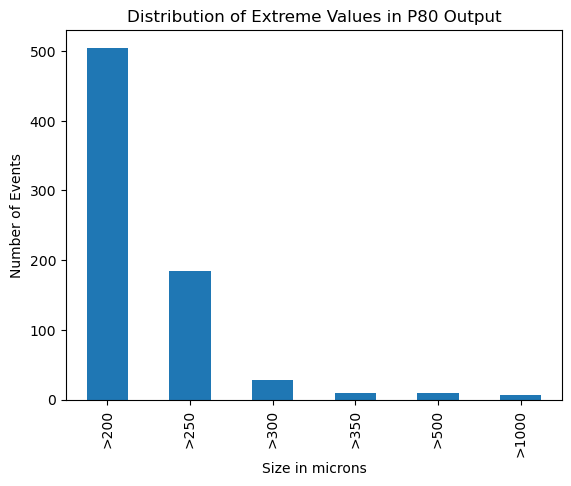

In [33]:
# Visual representation of the previously identified outliers in P80

atipicos_P80.T.plot(kind='bar', legend=False)
plt.title('Distribution of Extreme Values in P80 Output')
plt.xlabel('Size in microns')
plt.ylabel('Number of Events')

The acceptable output size range (P80) is between 100 and 300 microns.  
There are 10 data points that fall well above this range.  
Ideally, the process engineering team should be consulted to determine whether these values are due to process failures or operational downtimes.  
However, for the purposes of this analysis — and given that they represent only 10 out of 1,000 entries (1%) — these rows will be excluded from the dataset.

In [34]:
# Remove rows where P80 sizes are greater than 400 microns

data_copy = data_copy[data_copy['P80_Salida_micrones'] <= 400]
data_copy.describe()

,Dureza_BWI,TPH,Consumo_Energia_kWh,P80_Entrada_micrones,P80_Salida_micrones,Porcentaje_Solidos,RPM_Molino,Horas_Operacion,kWh_por_Ton,Reduccion_P80
count,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000
mean,12.070387,1501.699792,1197.074974,10004.099896,199.298647,62.501769,11.968757,21.991779,0.036688,9804.801249
std,1.919686,150.942563,99.530265,2001.458132,50.117189,4.363249,1.467292,1.138038,0.005283,2002.723244
min,5.900000,1072.000000,908.800000,1892.000000,48.000000,55.000000,7.300000,20.000000,0.022000,1666.000000
25%,10.700000,1401.000000,1130.100000,8656.000000,164.000000,58.700000,11.000000,21.000000,0.033000,8431.000000
50%,12.100000,1502.000000,1196.200000,10121.000000,200.000000,62.600000,11.925000,22.000000,0.036000,9920.000000
75%,13.400000,1606.000000,1262.125000,11337.000000,234.000000,66.300000,13.000000,23.000000,0.040000,11161.000000
max,19.200000,2033.000000,1507.600000,15062.000000,339.000000,70.000000,16.700000,24.000000,0.055000,14819.000000


In [ ]:
# We observe outliers in the solids percentage.

porc_menor_58 = (data_copy['Porcentaje_Solidos'] <= 58).sum()
porc_menor_55 = (data_copy['Porcentaje_Solidos'] <= 55).sum()
porc_menor_45 = (data_copy['Porcentaje_Solidos'] <= 45).sum()
porc_menor_40 = (data_copy['Porcentaje_Solidos'] <= 40).sum()

atipicos_porc_solidos = pd.DataFrame({'porc_men_58':[porc_menor_58],
                                      'porc_men_55':[porc_menor_55],
                                      'porc_men_45':[porc_menor_45],
                                      'porc_men_40':[porc_menor_40]}
                                     )
atipicos_porc_solidos.head()

,porc_men_58,porc_men_55,porc_men_45,porc_men_40
0,219,13,10,10


It is observed that there are 10 outlier values significantly below 55%.  
Since we have already removed the 10 entries with errors in P80, these represent a different set of 10 entries, this time with errors in the Solids Percentage.  
Given that they account for only 1% of the dataset, it is decided to remove these entries as well.

In [35]:
# Remove entries with outlier values in Solids Percentage

data_copy = data_copy[data_copy['Porcentaje_Solidos'] >= 50]
data_copy.describe()

,Dureza_BWI,TPH,Consumo_Energia_kWh,P80_Entrada_micrones,P80_Salida_micrones,Porcentaje_Solidos,RPM_Molino,Horas_Operacion,kWh_por_Ton,Reduccion_P80
count,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000
mean,12.070387,1501.699792,1197.074974,10004.099896,199.298647,62.501769,11.968757,21.991779,0.036688,9804.801249
std,1.919686,150.942563,99.530265,2001.458132,50.117189,4.363249,1.467292,1.138038,0.005283,2002.723244
min,5.900000,1072.000000,908.800000,1892.000000,48.000000,55.000000,7.300000,20.000000,0.022000,1666.000000
25%,10.700000,1401.000000,1130.100000,8656.000000,164.000000,58.700000,11.000000,21.000000,0.033000,8431.000000
50%,12.100000,1502.000000,1196.200000,10121.000000,200.000000,62.600000,11.925000,22.000000,0.036000,9920.000000
75%,13.400000,1606.000000,1262.125000,11337.000000,234.000000,66.300000,13.000000,23.000000,0.040000,11161.000000
max,19.200000,2033.000000,1507.600000,15062.000000,339.000000,70.000000,16.700000,24.000000,0.055000,14819.000000


The final decision is what to do with the entries labeled as "Unknown" in the "Mineral_Type" category.  
Since they represent only 2% of the total dataset, we will choose to remove these entries as well.  
If the number had been higher, we would have analyzed their behavior to determine whether they resembled any of the other categories or showed distinct characteristics.

In [36]:
# Remove rows where the value in the "Tipo_Mineral" column is "Desconocido"

data_copy = data_copy[data_copy['Tipo_Mineral'] != "Desconocido"]

# Verify data integrity
data_copy.describe()

,Dureza_BWI,TPH,Consumo_Energia_kWh,P80_Entrada_micrones,P80_Salida_micrones,Porcentaje_Solidos,RPM_Molino,Horas_Operacion,kWh_por_Ton,Reduccion_P80
count,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000
mean,12.070387,1501.699792,1197.074974,10004.099896,199.298647,62.501769,11.968757,21.991779,0.036688,9804.801249
std,1.919686,150.942563,99.530265,2001.458132,50.117189,4.363249,1.467292,1.138038,0.005283,2002.723244
min,5.900000,1072.000000,908.800000,1892.000000,48.000000,55.000000,7.300000,20.000000,0.022000,1666.000000
25%,10.700000,1401.000000,1130.100000,8656.000000,164.000000,58.700000,11.000000,21.000000,0.033000,8431.000000
50%,12.100000,1502.000000,1196.200000,10121.000000,200.000000,62.600000,11.925000,22.000000,0.036000,9920.000000
75%,13.400000,1606.000000,1262.125000,11337.000000,234.000000,66.300000,13.000000,23.000000,0.040000,11161.000000
max,19.200000,2033.000000,1507.600000,15062.000000,339.000000,70.000000,16.700000,24.000000,0.055000,14819.000000


# 3. DATA ANALYSIS

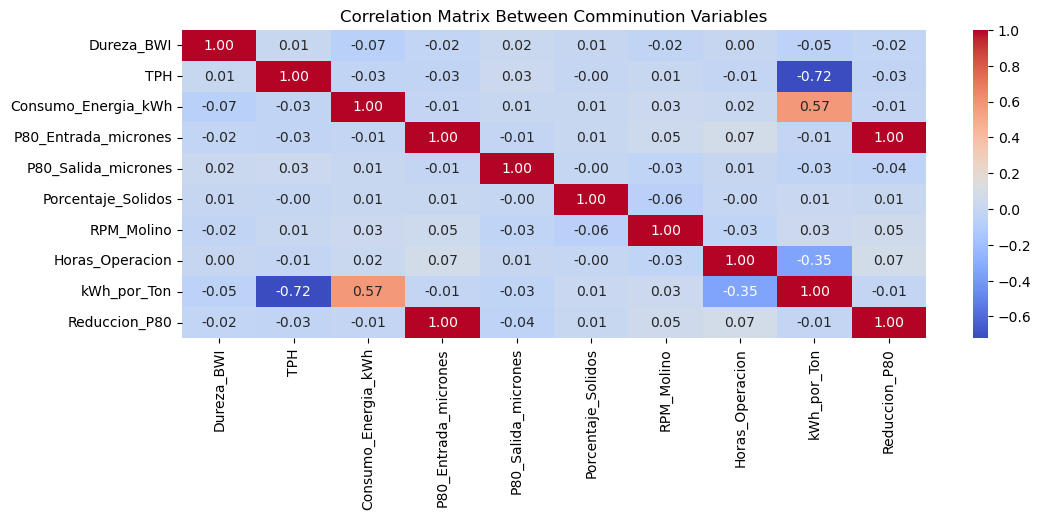

In [37]:
# Check correlation between variables
correlacion = data_copy.corr(numeric_only=True)

# Visualization with Heatmap
plt.figure(figsize=(12,4))
sb.heatmap(correlacion, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix Between Comminution Variables')
plt.show()

According to the correlation analysis (using the Pearson method), we observe that as the throughput (tons per hour) increases, the energy consumption per ton processed decreases.  
There is also a mild inverse correlation between operating hours and energy consumption per ton.  
Aside from these, there is virtually no significant correlation among the remaining variables.

Next, we will examine whether the correlation patterns vary depending on the mineral type.

<function matplotlib.pyplot.show(close=None, block=None)>

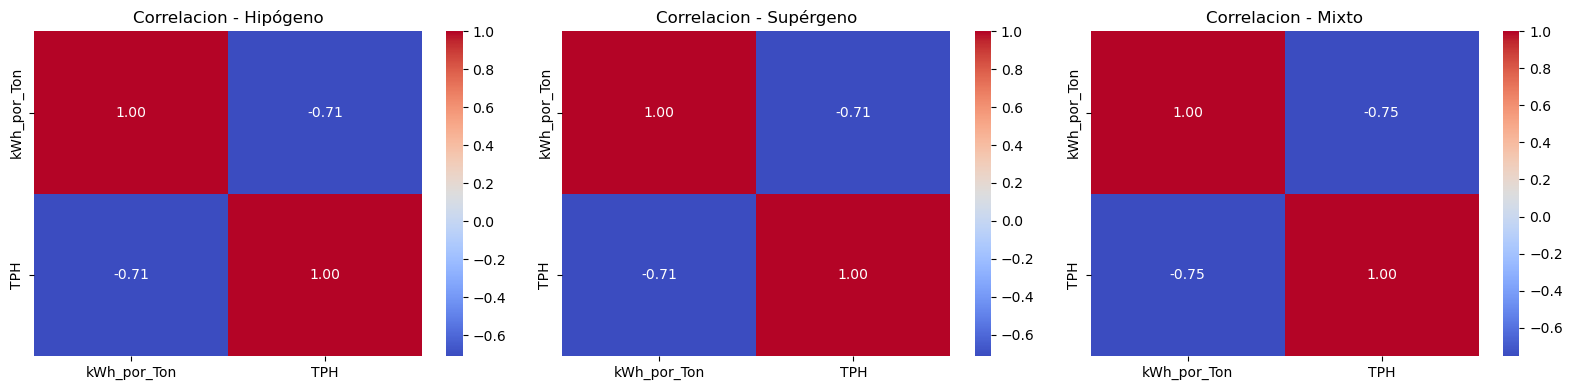

In [38]:
tipos_min = ['Hipógeno', 'Supérgeno', 'Mixto']

# Create the figure and axes
fig, axes = plt.subplots(1, 3, figsize=(16,4))

axes = axes.flatten()

for i, tipo in enumerate(tipos_min):
    df_tipo = data_copy[data_copy['Tipo_Mineral'] == tipo]
    
    corr = df_tipo[['kWh_por_Ton', 'TPH']].corr()

    sb.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", ax=axes[i])
    axes[i].set_title(f'Correlacion - {tipo.capitalize()}')

plt.tight_layout()
plt.show

It can be observed that the mineral type has little to no effect on the correlation between energy consumption per ton and throughput (tons processed per hour).

Below are the average values of the various variables for each mineral type.

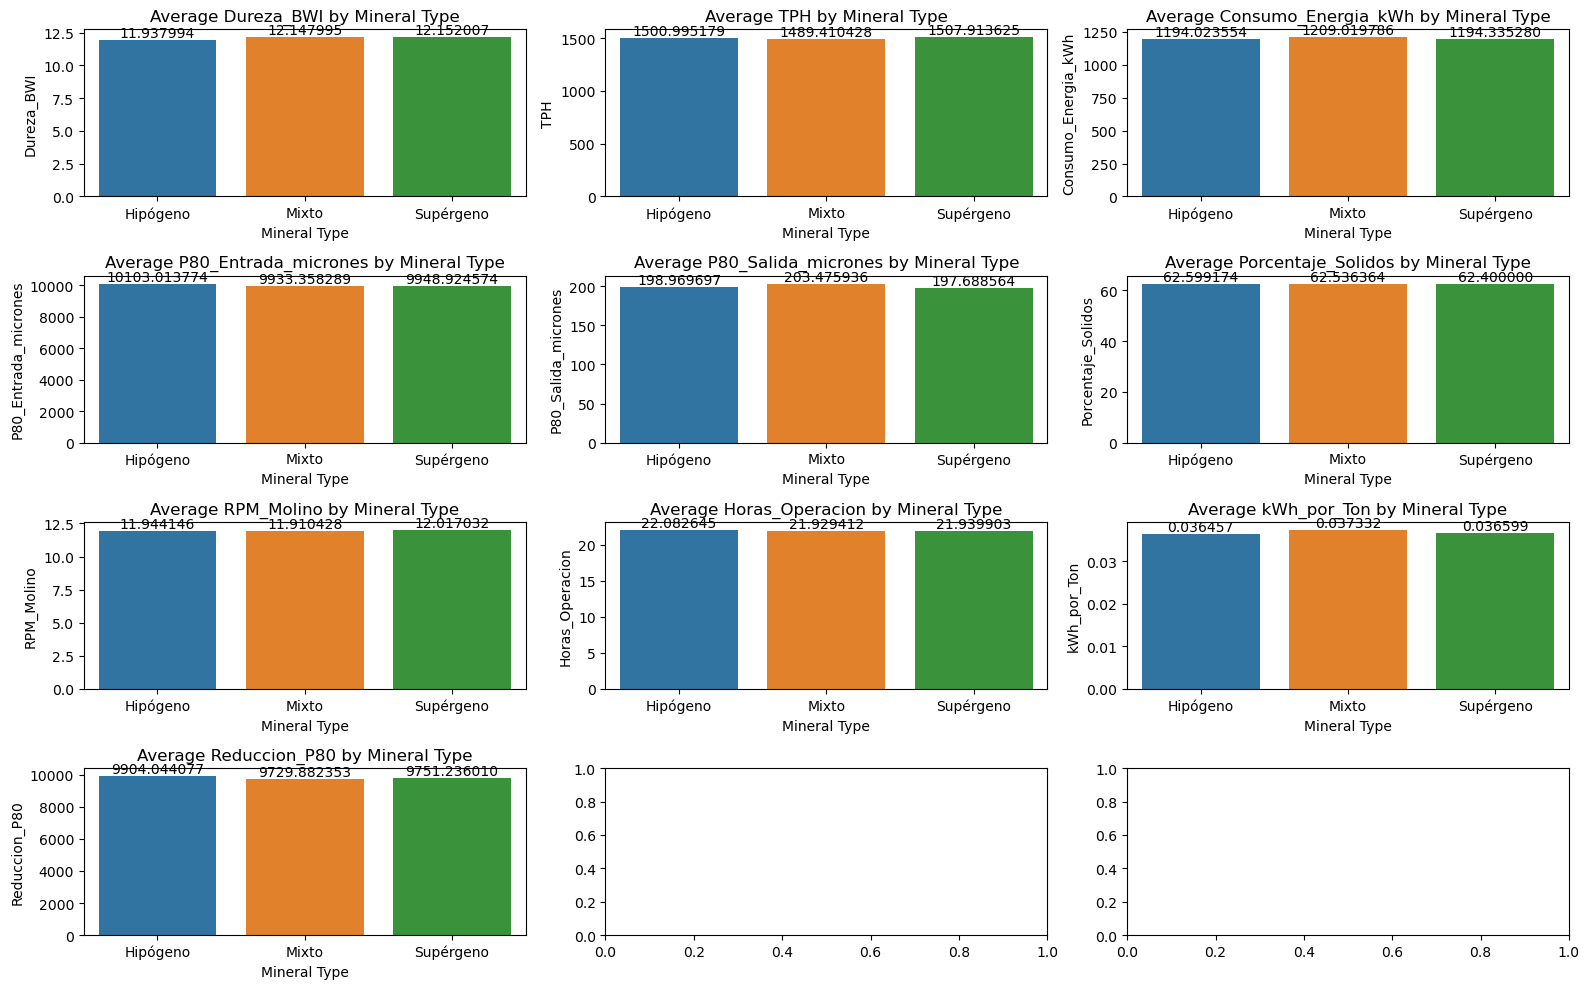

In [40]:
# Compare various variables by mineral type
variables = ['Dureza_BWI', 'TPH',
       'Consumo_Energia_kWh', 'P80_Entrada_micrones', 'P80_Salida_micrones',
       'Porcentaje_Solidos', 'RPM_Molino', 'Horas_Operacion', 'kWh_por_Ton',
       'Reduccion_P80']

df_grouped = data_copy.groupby('Tipo_Mineral')[variables].mean().reset_index()

fig, axes = plt.subplots(4, 3, figsize=(16, 10))
axes = axes.flatten()

for i, var in enumerate(variables):

    ax = axes[i]
    sb.barplot(data=df_grouped, x='Tipo_Mineral', y=var, ax=axes[i])

    for container in ax.containers:
        ax.bar_label(container, fmt='%2f')
        
    axes[i].set_title(f'Average {var} by Mineral Type')
    axes[i].set_ylabel(var)
    axes[i].set_xlabel('Mineral Type')

plt.tight_layout()
plt.show()

Interestingly, all variables show very similar values across the different mineral types.  
However, it is important to note once again that the dataset used in this project was artificially generated by AI.  
This may explain why it does not reflect the expected real-world behavior.

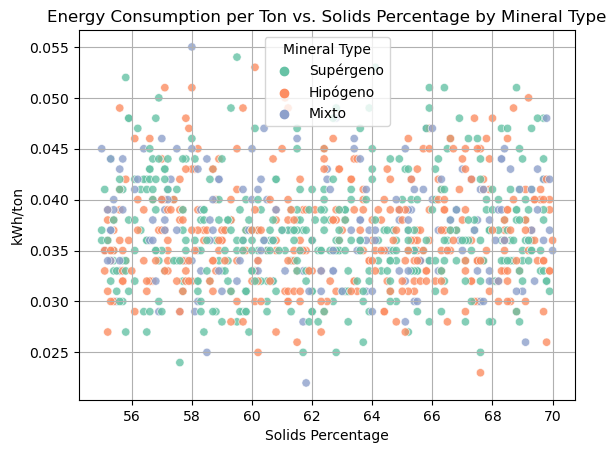

In [41]:
# Scatter plot to visualize energy consumption as a function of solids percentage for each mineral type

sb.scatterplot(
    data=data_copy,
    x='Porcentaje_Solidos',
    y='kWh_por_Ton',
    hue='Tipo_Mineral',
    palette='Set2',
    alpha=0.8
)

plt.title('Energy Consumption per Ton vs. Solids Percentage by Mineral Type')
plt.xlabel('Solids Percentage')
plt.ylabel('kWh/ton')
plt.legend(title='Mineral Type')
plt.grid(True)
plt.show()

No relevant patterns were found.

c:\Users\basti\anaconda3\envs\myenv\lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


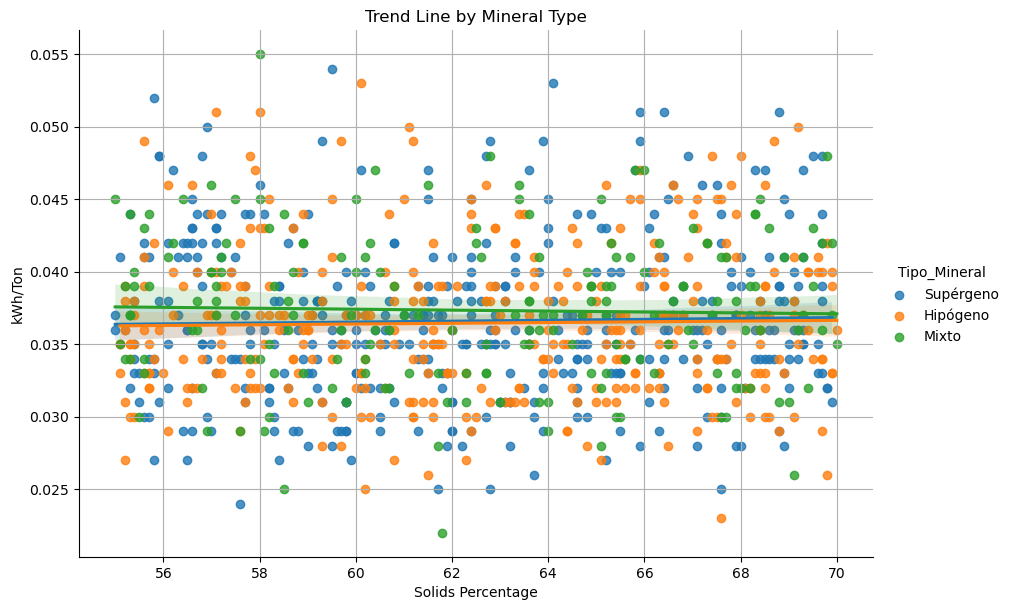

In [42]:
# Since the scatter plot did not reveal clear trends, a trend line plot is generated

sb.lmplot(
    data=data_copy,
    x='Porcentaje_Solidos',
    y='kWh_por_Ton',
    hue='Tipo_Mineral',
    ci=95,
    markers='o',
    aspect=1.5,
    height=6
)

plt.title("Trend Line by Mineral Type")
plt.xlabel('Solids Percentage')
plt.ylabel('kWh/Ton')
plt.grid(True)
plt.show()

A slight trend is observed indicating greater energy efficiency when processing Mixed-type minerals with a higher solids percentage.

c:\Users\basti\anaconda3\envs\myenv\lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
C:\Users\basti\AppData\Local\Temp\ipykernel_6596\88732501.py:18: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


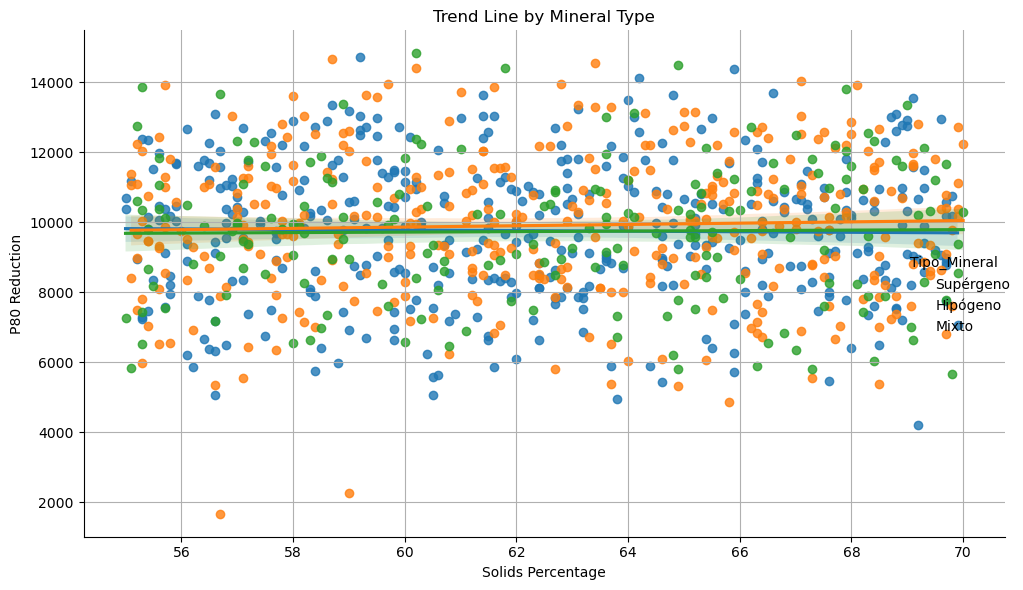

In [43]:
# Evaluate size reduction as a function of solids percentage

sb.lmplot(
    data=data_copy,
    x='Porcentaje_Solidos',
    y='Reduccion_P80',
    hue='Tipo_Mineral',
    ci=95,
    markers='o',
    aspect=1.5,
    height=6
)

plt.title("Trend Line by Mineral Type")
plt.xlabel('Solids Percentage')
plt.ylabel('P80 Reduction')
plt.grid(True)
plt.tight_layout()
plt.show()

c:\Users\basti\anaconda3\envs\myenv\lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


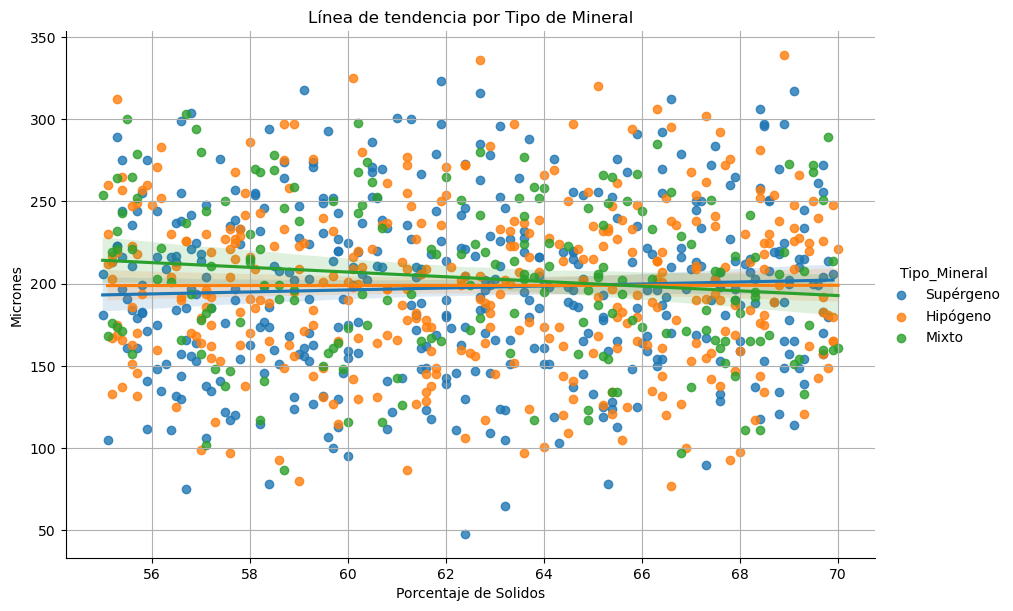

In [ ]:
sb.lmplot(
    data=data_copy,
    x='Porcentaje_Solidos',
    y='P80_Salida_micrones',
    hue='Tipo_Mineral',
    ci=95,
    markers='o',
    aspect=1.5,
    height=6
)

plt.title("Línea de tendencia por Tipo de Mineral")
plt.xlabel('Porcentaje de Solidos')
plt.ylabel('Micrones')
plt.grid(True)
plt.show()

Once again, Supergene and Hypogene minerals exhibit consistent behavior as the solids percentage varies.  
However, Mixed-type minerals show greater size reduction when processed at higher solids percentages.  
Based on this and the previous plot, it is recommended to operate with a solids percentage between 66% and 70% for Mixed minerals,  
as this would result in higher energy efficiency and improved particle size reduction.

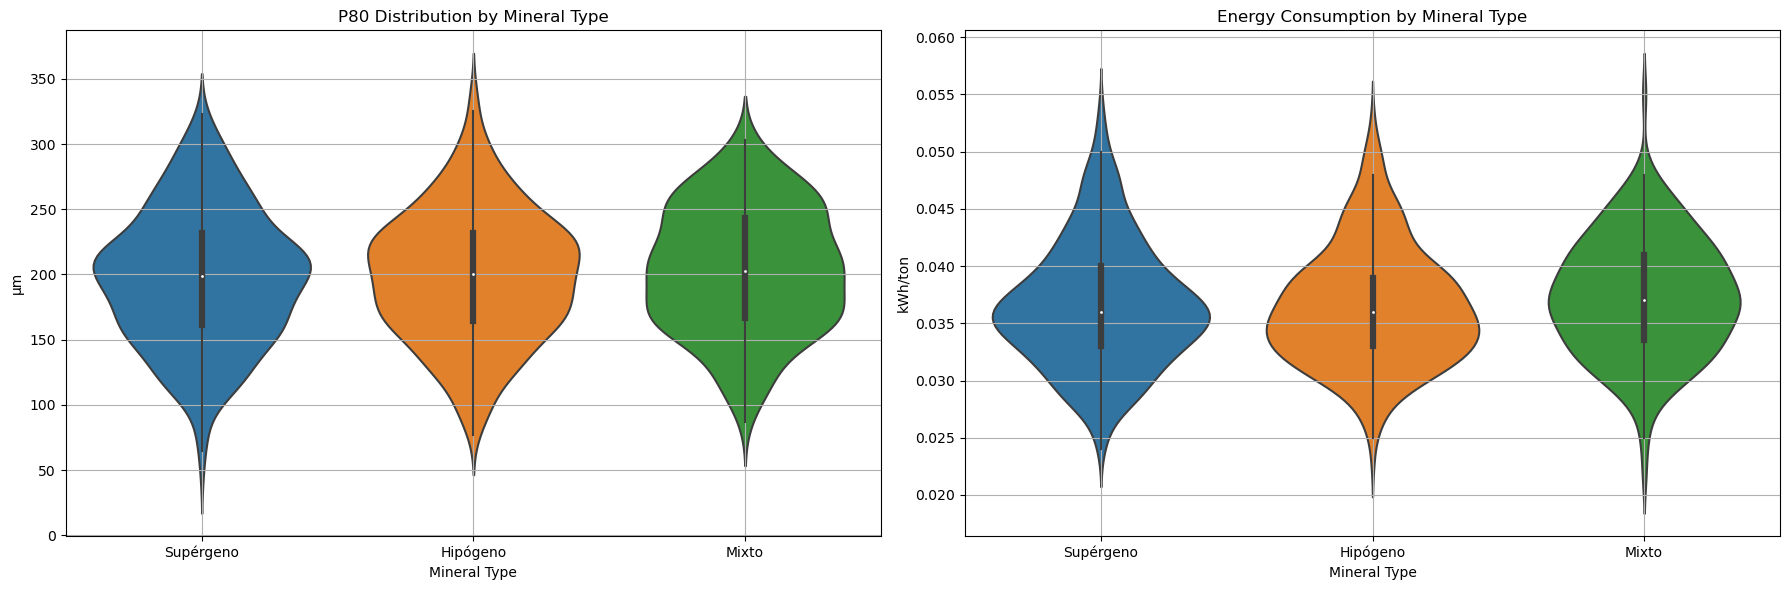

In [44]:
# Visualize the distribution of P80 and energy consumption by Mineral Type
fig, axes = plt.subplots(1, 2, figsize=(18,6))

# Violin plot for P80
sb.violinplot(data=data_copy, x='Tipo_Mineral', y='P80_Salida_micrones', inner='box', ax=axes[0])
axes[0].set_title('P80 Distribution by Mineral Type')
axes[0].set_xlabel('Mineral Type')
axes[0].set_ylabel('μm')
axes[0].grid(True)

# Violin plot for energy consumption per ton of ore
sb.violinplot(data=data_copy, x='Tipo_Mineral', y='kWh_por_Ton', inner='box', ax=axes[1])
axes[1].set_title('Energy Consumption by Mineral Type')
axes[1].set_xlabel('Mineral Type')
axes[1].set_ylabel('kWh/ton')
axes[1].grid(True)

plt.tight_layout()
plt.show()

The violin plot appears slightly narrower and lower for the Supergene mineral type compared to the Hypogene, suggesting a greater particle size reduction for Supergene minerals.  
However, there is also a higher concentration of events in the 250 to 300 micron range for the Supergene type than for the Hypogene.  
This should be further evaluated, as theoretically, Supergene minerals are softer than Hypogene ones, and thus should exhibit more events clustered closer to the average.  
On the other hand, the Mixed mineral type shows a more butterfly-shaped distribution, indicating that it sometimes behaves more like Hypogene and other times like Supergene.

Regarding energy consumption, a slightly greater efficiency is observed when processing Hypogene minerals.  
Again, it is recommended to review the processing parameters for Supergene minerals, since—being softer—they should theoretically consume less energy than Hypogene minerals.  
In the case of Mixed minerals, a slightly higher energy consumption is observed, along with a more varied distribution of consumption events.  
This can be attributed to the mixed nature of the ore, which in some cases contains more Supergene and in others more Hypogene components.

Next, the distribution of P80 output and energy consumption is plotted again,  
this time segmented by work shift.

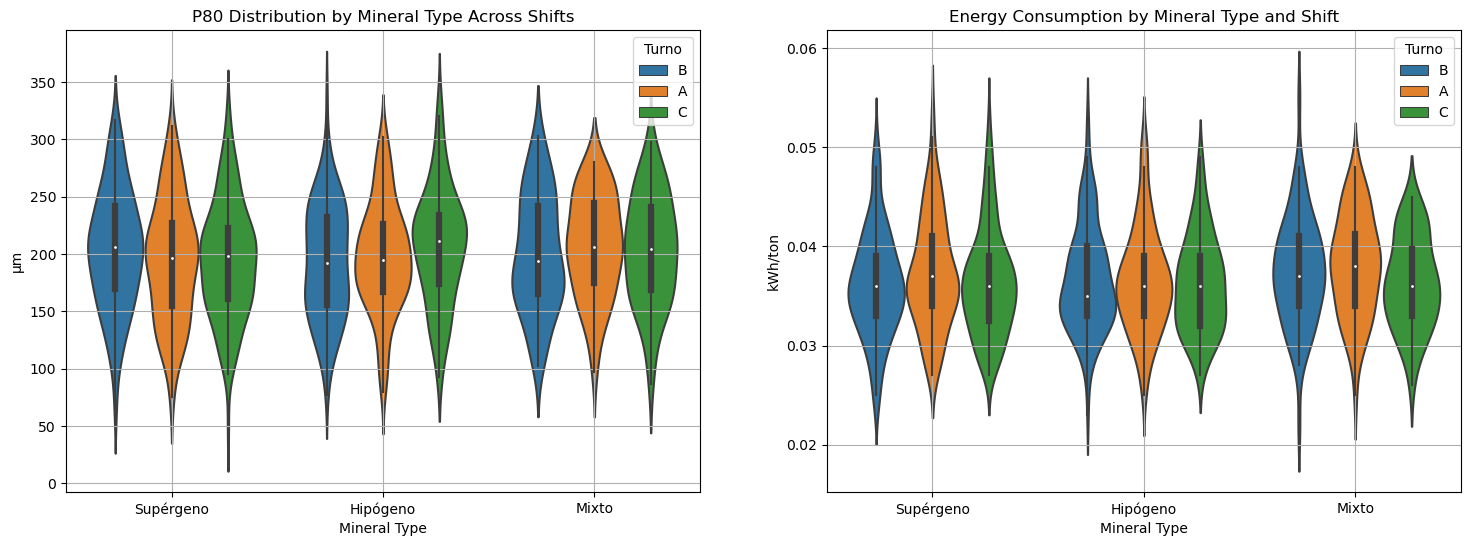

In [45]:
# Visualize the distribution of P80 and energy consumption by Mineral Type and Shift
fig, axes = plt.subplots(1, 2, figsize=(18,6))

# Violin plot for P80
sb.violinplot(data=data_copy, x='Tipo_Mineral', y='P80_Salida_micrones', inner='box', hue='Turno', ax=axes[0])
axes[0].set_title('P80 Distribution by Mineral Type Across Shifts')
axes[0].set_xlabel('Mineral Type')
axes[0].set_ylabel('μm')
axes[0].grid(True)

# Violin plot for energy consumption per ton
sb.violinplot(data=data_copy, x='Tipo_Mineral', y='kWh_por_Ton', hue='Turno', inner='box', ax=axes[1])
axes[1].set_title('Energy Consumption by Mineral Type and Shift')
axes[1].set_xlabel('Mineral Type')
axes[1].set_ylabel('kWh/ton')
axes[1].grid(True)

plt.show()

It is observed that Shift C achieves slightly finer particles when processing Supergene ore compared to Shifts A and B.  
Conversely, the opposite occurs when processing Hypogene ore.  
Since shifts rotate daily, no clear conclusion can be drawn regarding the effect of working during the day or night.

Additionally, Shift A tends to consume slightly more energy than the other shifts across all three mineral types.  
For all shifts, energy consumption is higher when processing Mixed ores.

**Combined observations:**

When processing Mixed ores, all three shifts show more frequent cases of both higher energy consumption and coarser P80 particle sizes.  
This may be due to a higher-than-estimated presence of harder material.  
It is advisable to re-evaluate the processing parameters selected for Mixed ores, as this represents a potential opportunity for improvement.

Next, the distribution of mill RPM and solids percentage is plotted for each mineral type across the different shifts.

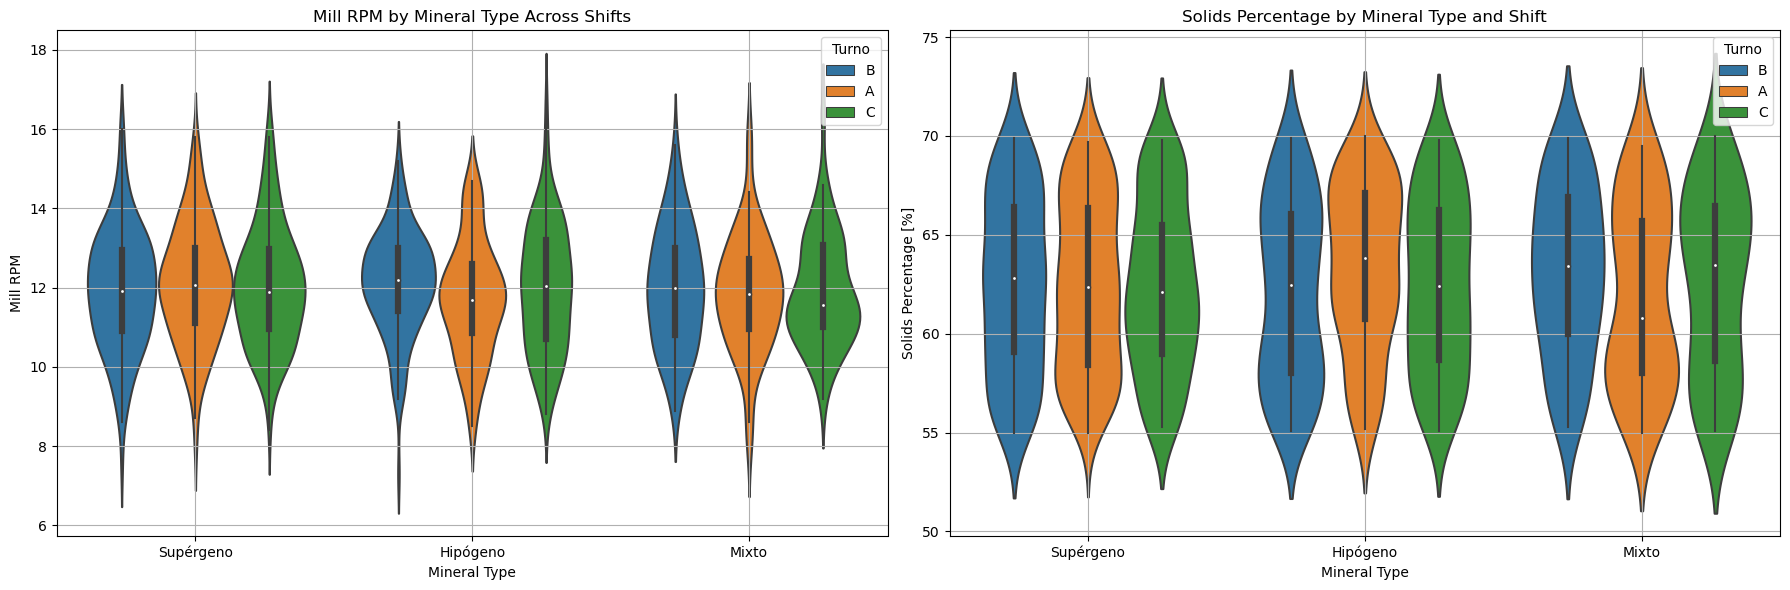

In [46]:
# Plot the distribution of mill RPM by shift and mineral type

fig, axes = plt.subplots(1, 2, figsize=(18,6))

sb.violinplot(data=data_copy, x='Tipo_Mineral', y='RPM_Molino', inner='box', hue='Turno', ax=axes[0])
axes[0].set_title('Mill RPM by Mineral Type Across Shifts')
axes[0].set_xlabel('Mineral Type')
axes[0].set_ylabel('Mill RPM')
axes[0].grid(True)

# Plot the solids percentage used in each shift and mineral type

sb.violinplot(data=data_copy, x='Tipo_Mineral', y='Porcentaje_Solidos', hue='Turno', inner='box', ax=axes[1])
axes[1].set_title('Solids Percentage by Mineral Type and Shift')
axes[1].set_xlabel('Mineral Type')
axes[1].set_ylabel('Solids Percentage [%]')
axes[1].grid(True)

plt.tight_layout()


It is observed that Shift A uses different solids percentages compared to the other two shifts for the same mineral types.  
Shift A should aim to operate with parameters more aligned with the other shifts.  
This could help achieve a more consistent energy consumption—unless there are specific operational reasons related to that shift that fall outside the scope of this analysis.

Next, we will examine some process variables over time ranges in order to identify potential seasonal patterns.

In [47]:
# Convert the 'Fecha' column from type 'object' to 'datetime'.

data_copy['Fecha'] = pd.to_datetime(data_copy['Fecha'])
print(data_copy['Fecha'].head(3))

0   2024-01-01
1   2024-01-02
2   2024-01-03
Name: Fecha, dtype: datetime64[ns]


In [48]:
# Create a new column with the month and another with the day of the week
data_copy['mes'] = data_copy['Fecha'].dt.to_period('M')
data_copy['dia'] = data_copy['Fecha'].dt.day_name()

# Since 'locale' doesn't work, we manually translate the days of the week

dias_es = {
    'Monday': 'Lunes',
    'Tuesday': 'Martes',
    'Wednesday': 'Miércoles',
    'Thursday': 'Jueves',
    'Friday': 'Viernes',
    'Saturday': 'Sábado',
    'Sunday': 'Domingo'
}

data_copy['dia'] = data_copy['Fecha'].dt.day_name().map(dias_es)

print(data_copy['dia'].head(3))
print(data_copy['mes'].head(3))

0        Lunes
1       Martes
2    Miércoles
Name: dia, dtype: object
0    2024-01
1    2024-01
2    2024-01
Name: mes, dtype: period[M]


In [49]:
# Create a new table with all variables of interest, grouped by the different months recorded across the years.

data_por_mes = data_copy.groupby('mes')[variables].mean().reset_index() ##FORMATO period[M]
data_por_mes['mes_dt'] = data_por_mes['mes'].dt.to_timestamp() ##FORMATO timestamp
data_por_mes['mes_str'] = data_por_mes['mes_dt'].dt.strftime('%b %Y') ##FORMATO String

data_por_mes.head()

,mes,Dureza_BWI,TPH,Consumo_Energia_kWh,P80_Entrada_micrones,P80_Salida_micrones,Porcentaje_Solidos,RPM_Molino,Horas_Operacion,kWh_por_Ton,Reduccion_P80,mes_dt,mes_str
0,2024-01,11.762097,1479.774194,1202.190323,10228.677419,199.354839,63.164516,11.866129,21.600000,0.038226,10029.322581,2024-01-01,Jan 2024
1,2024-02,12.677679,1519.848214,1181.347321,9475.392857,202.250000,62.678571,11.660714,21.635714,0.036643,9273.142857,2024-02-01,Feb 2024
2,2024-03,11.993333,1543.541667,1221.469167,10037.366667,197.100000,62.236667,12.226667,21.713333,0.037133,9840.266667,2024-03-01,Mar 2024
3,2024-04,12.070370,1534.666667,1189.578704,9398.518519,199.074074,62.500000,11.914815,22.140741,0.035333,9199.444444,2024-04-01,Apr 2024
4,2024-05,12.309677,1481.225806,1211.838710,9961.774194,210.129032,63.154839,12.116935,21.987097,0.037581,9751.645161,2024-05-01,May 2024


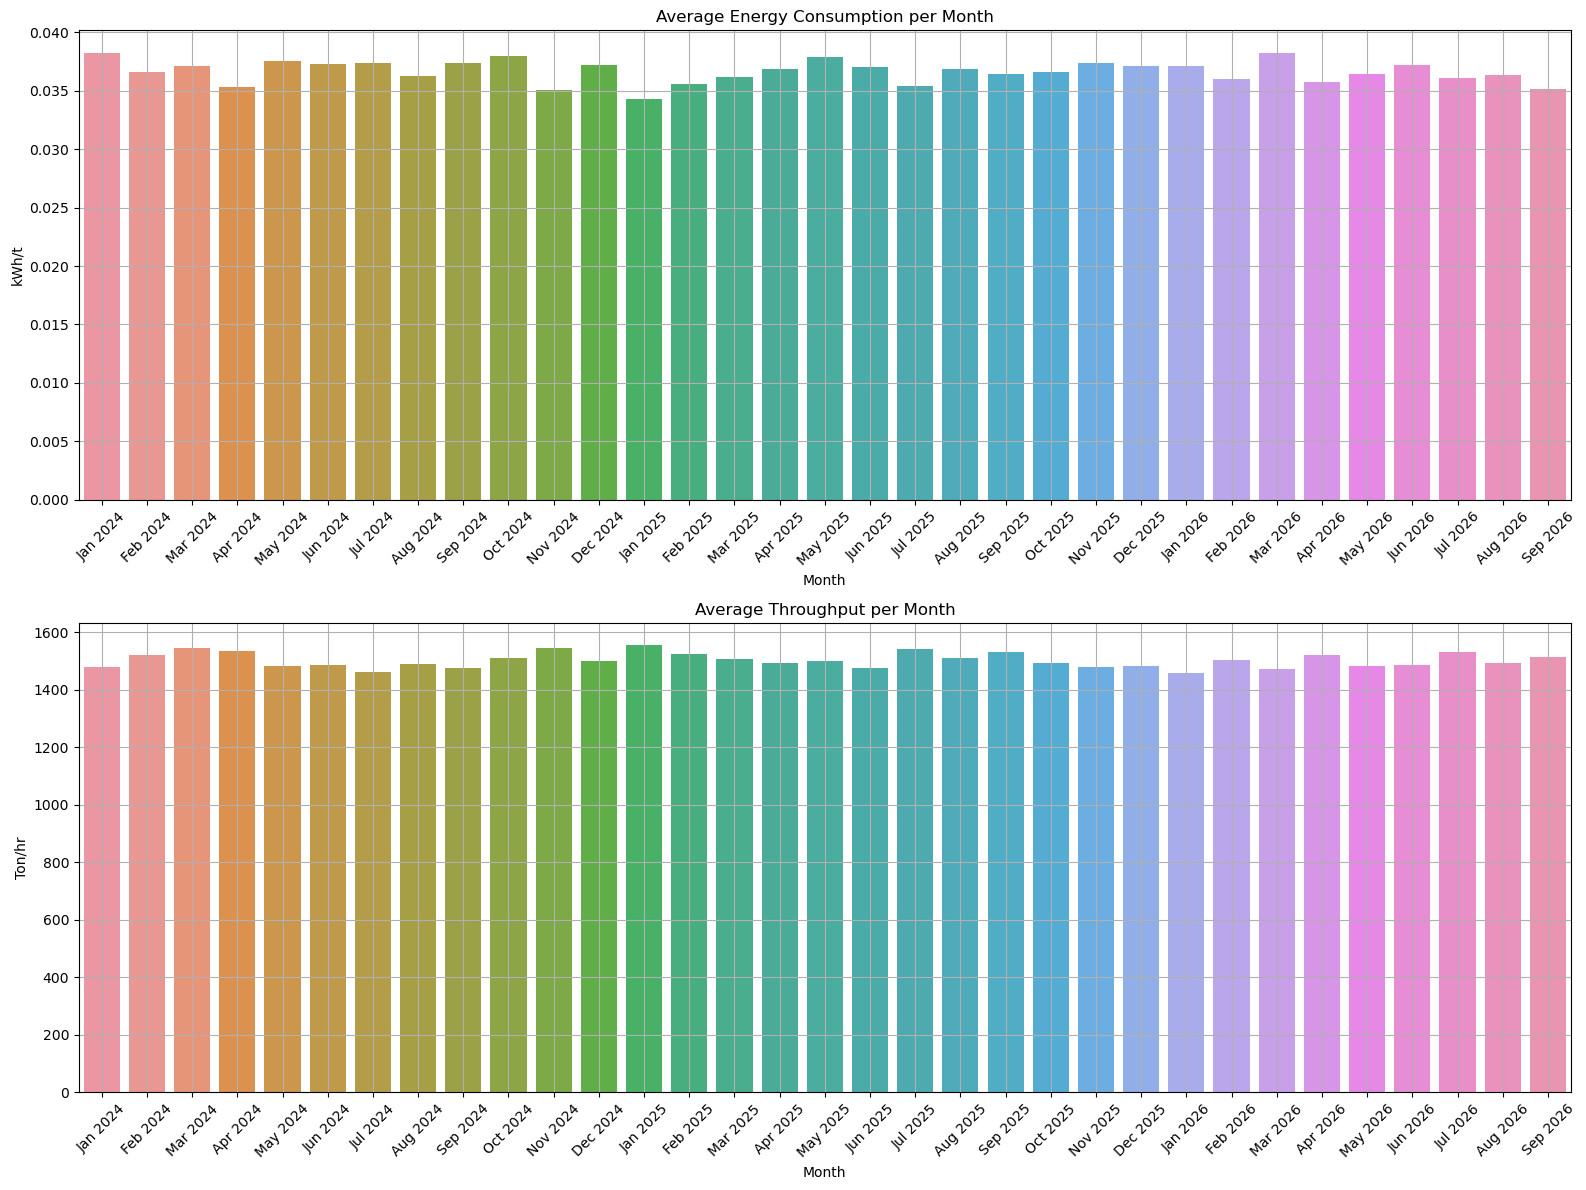

In [50]:
# Plotting
fig, axes = plt.subplots(2, 1, figsize=(16,12))
axes = axes.flatten()

# Average energy consumption per ton processed across recorded months
sb.barplot(data=data_por_mes, x='mes_str', y='kWh_por_Ton', ax=axes[0])
axes[0].set_title('Average Energy Consumption per Month')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('kWh/t')
axes[0].grid(True)

# Average throughput across recorded months
sb.barplot(data=data_por_mes, x='mes_str', y='TPH', ax=axes[1])
axes[1].set_title('Average Throughput per Month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Ton/hr')
axes[1].grid(True)

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

We observe that there are months in which energy consumption was lower compared to others, while the throughput (tons of ore processed per hour) remained similar or even higher in some cases. For example, in April 2024, November 2024, and January 2025, energy consumption was among the lowest, while the throughput was among the highest. This aligns with the previously identified inverse correlation between energy consumption and TPH (tons per hour).

Next, the same variables will be evaluated, but this time by averaging the monthly means across different years, in order to obtain the average for each calendar month. This approach aims to identify potential seasonal patterns.

In [51]:
# Add a new column with month names only
data_por_mes['str_solo_mes'] = data_por_mes['mes_dt'].dt.strftime('%B')

# Group by month name and calculate the mean of all variables
data_por_solo_mes = data_por_mes.groupby('str_solo_mes')[variables].mean().reset_index()

# Sort the months in calendar order
ordered_months = ['January', 'February', 'March', 'April', 'May', 'June',
                  'July', 'August', 'September', 'October', 'November', 'December']
data_por_solo_mes['str_solo_mes'] = pd.Categorical(data_por_solo_mes['str_solo_mes'], categories=ordered_months, ordered=True)
data_por_solo_mes = data_por_solo_mes.sort_values('str_solo_mes').reset_index()

data_por_solo_mes.head()

,index,str_solo_mes,Dureza_BWI,TPH,Consumo_Energia_kWh,P80_Entrada_micrones,P80_Salida_micrones,Porcentaje_Solidos,RPM_Molino,Horas_Operacion,kWh_por_Ton,Reduccion_P80
0,4,January,12.212346,1497.775922,1181.176635,10060.899616,192.965899,62.205553,11.853412,21.924365,0.036548,9867.933717
1,3,February,12.261264,1515.349359,1192.269002,9914.157509,202.418498,62.269322,11.911355,22.162363,0.036086,9711.739011
2,7,March,12.040556,1507.752778,1208.458056,9826.155556,203.566667,62.328889,12.113056,21.833333,0.037200,9622.588889
3,0,April,11.928198,1516.413075,1190.391369,10025.315081,204.904960,62.279262,11.983243,22.106444,0.035987,9820.410121
4,8,May,12.246281,1487.775269,1200.297348,10038.102509,199.743011,63.451613,12.094812,21.926810,0.037316,9838.359498


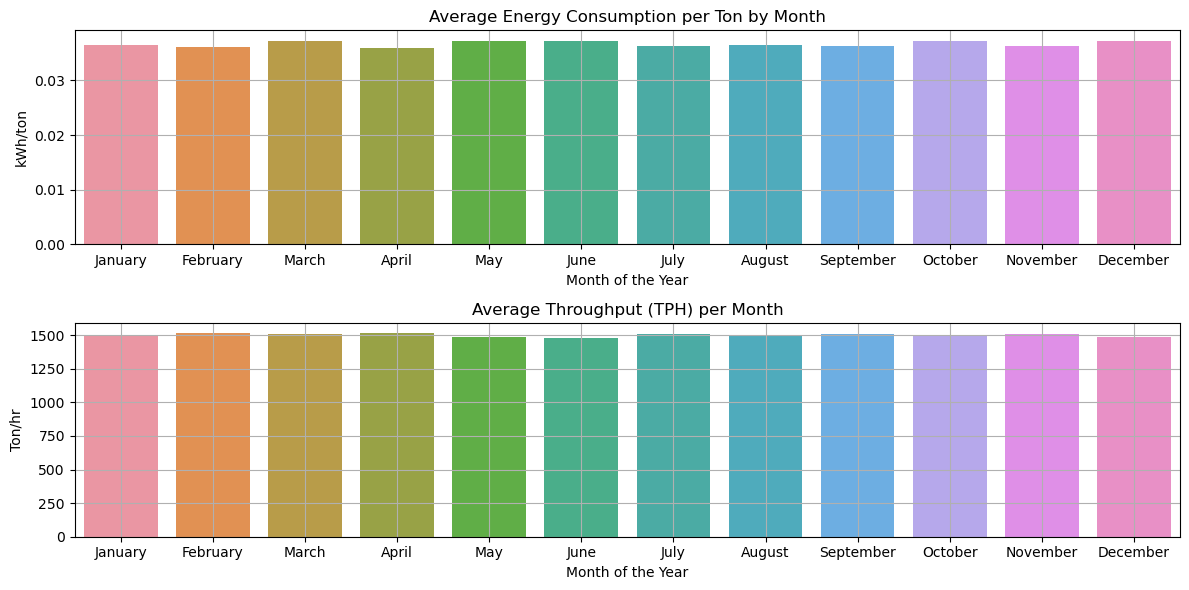

In [52]:
# Plotting

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes = axes.flatten()

# Average energy consumption per ton by month
sb.barplot(data=data_por_solo_mes, x='str_solo_mes', y='kWh_por_Ton', ax=axes[0])
axes[0].set_title('Average Energy Consumption per Ton by Month')
axes[0].set_xlabel('Month of the Year')
axes[0].set_ylabel('kWh/ton')
axes[0].grid(True)

# Average throughput (TPH) by month
sb.barplot(data=data_por_solo_mes, x='str_solo_mes', y='TPH', ax=axes[1])
axes[1].set_title('Average Throughput (TPH) per Month')
axes[1].set_xlabel('Month of the Year')
axes[1].set_ylabel('Ton/hr')
axes[1].grid(True)

plt.tight_layout()

No seasonal patterns are observed. However, while the average monthly throughput (tons per hour) remains fairly stable throughout the year, energy consumption shows slightly more variation.

Next, the average annual use of solids percentage is plotted to identify any seasonal patterns and/or to relate it to the previously observed trends in energy consumption.

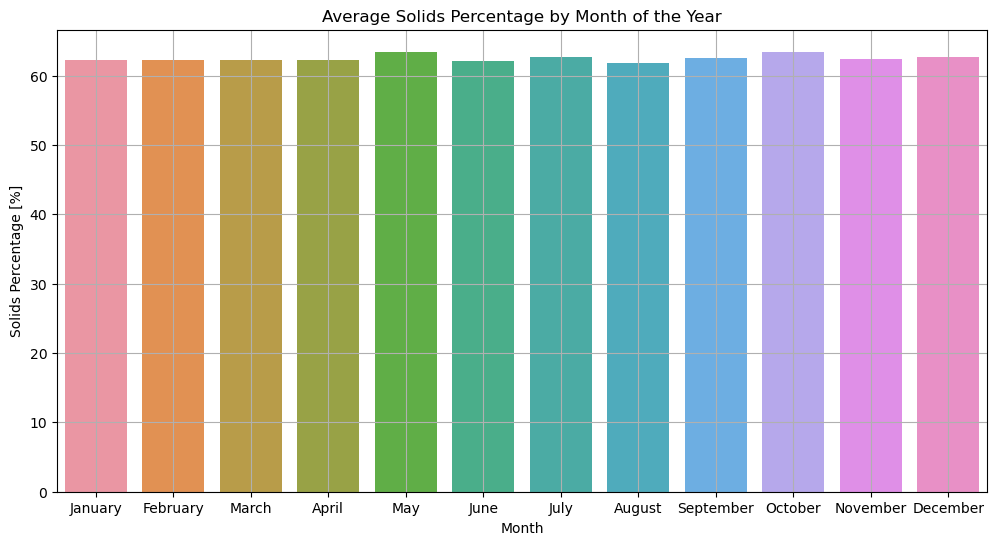

In [53]:
# Create the bar chart

plt.figure(figsize=(12,6))
sb.barplot(data=data_por_solo_mes, x='str_solo_mes', y='Porcentaje_Solidos')
plt.title('Average Solids Percentage by Month of the Year')
plt.xlabel('Month')
plt.ylabel('Solids Percentage [%]')
plt.grid(True)
plt.show()

No relevant observations.

Next, we will analyze the events in which it was decided to operate the mill at less than 10 RPM. The objective is to identify relevant observations that might explain the reason behind this decision.

In [54]:
# Let's review the cases where RPM was less than 10
data_menor_10_RPM = data_copy[data_copy['RPM_Molino'] < 10]
data_menor_10_RPM.info()

<class 'pandas.core.frame.DataFrame'>
Index: 74 entries, 26 to 998
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Fecha                 74 non-null     datetime64[ns]
 1   Turno                 74 non-null     object        
 2   Tipo_Mineral          74 non-null     object        
 3   Dureza_BWI            74 non-null     float64       
 4   TPH                   74 non-null     float64       
 5   Consumo_Energia_kWh   74 non-null     float64       
 6   P80_Entrada_micrones  74 non-null     float64       
 7   P80_Salida_micrones   74 non-null     float64       
 8   Porcentaje_Solidos    74 non-null     float64       
 9   RPM_Molino            74 non-null     float64       
 10  Horas_Operacion       74 non-null     float64       
 11  kWh_por_Ton           74 non-null     float64       
 12  Reduccion_P80         74 non-null     float64       
 13  mes                   74 

In [ ]:
data_menor_10_RPM.describe()

,Fecha,Dureza_BWI,TPH,Consumo_Energia_kWh,P80_Entrada_micrones,P80_Salida_micrones,Porcentaje_Solidos,RPM_Molino,Horas_Operacion,kWh_por_Ton,Reduccion_P80
count,74,74.000000,74.000000,74.00000,74.000000,74.000000,74.000000,74.000000,74.000000,74.000000,74.000000
mean,2025-04-30 06:09:43.783783680,11.725338,1504.814189,1204.66723,10210.310811,197.324324,63.418919,9.314865,22.070270,0.036743,10012.986486
min,2024-01-27 00:00:00,5.900000,1187.000000,982.50000,5076.000000,78.000000,55.200000,7.300000,20.000000,0.023000,4857.000000
25%,2024-08-14 12:00:00,10.600000,1427.000000,1125.45000,8573.750000,162.000000,59.700000,9.100000,21.125000,0.033000,8365.250000
50%,2025-05-20 12:00:00,11.700000,1505.500000,1204.65000,10453.000000,202.000000,63.450000,9.400000,22.050000,0.036500,10249.500000
75%,2025-12-17 12:00:00,12.675000,1589.000000,1290.38125,11765.500000,227.000000,67.400000,9.800000,23.200000,0.041000,11502.250000
max,2026-09-25 00:00:00,15.700000,1964.000000,1453.60000,14083.000000,297.000000,69.700000,9.900000,23.900000,0.047000,13956.000000
std,NaN,1.699695,150.751724,111.31288,1952.195357,47.180826,4.237946,0.562695,1.156841,0.005547,1951.409771


There are 74 records where an RPM lower than 10 was chosen. From the statistical analysis of these records, it can be observed that the mean and standard deviation values do not differ significantly from those obtained from the original dataset.

In [55]:
# Review the number of events by Shift and Mineral Type

print(data_menor_10_RPM[['Turno']].apply(pd.Series.value_counts))
print(data_menor_10_RPM[['Tipo_Mineral']].apply(pd.Series.value_counts))

       Turno
Turno       
B         27
A         26
C         21
              Tipo_Mineral
Tipo_Mineral              
Hipógeno                33
Supérgeno               30
Mixto                   11


This may be due to the fact that the data were artificially generated, but there does not appear to be any relevant pattern explaining the application of lower mill RPM values.

# 4. Predictive Model

Once the exploratory data analysis was completed and relevant process observations identified, we proceed to build a simple predictive model using Random Forest. The objective is to predict the **P80 output value** based on the following process variables:

- Input P80 (F80)  
- Solids Percentage  
- Mineral Type  
- Hardness (BWI index)  
- Mill RPM  
- Operating Hours  

In [56]:
# Create a DataFrame with the data to be used for the model

data_modelo = data_copy[['P80_Entrada_micrones', 'Porcentaje_Solidos', 'Tipo_Mineral', 'Dureza_BWI', 'RPM_Molino', 'Horas_Operacion', 'P80_Salida_micrones']].copy()
data_modelo.describe()

,P80_Entrada_micrones,Porcentaje_Solidos,Dureza_BWI,RPM_Molino,Horas_Operacion,P80_Salida_micrones
count,961.000000,961.000000,961.000000,961.000000,961.000000,961.000000
mean,10004.099896,62.501769,12.070387,11.968757,21.991779,199.298647
std,2001.458132,4.363249,1.919686,1.467292,1.138038,50.117189
min,1892.000000,55.000000,5.900000,7.300000,20.000000,48.000000
25%,8656.000000,58.700000,10.700000,11.000000,21.000000,164.000000
50%,10121.000000,62.600000,12.100000,11.925000,22.000000,200.000000
75%,11337.000000,66.300000,13.400000,13.000000,23.000000,234.000000
max,15062.000000,70.000000,19.200000,16.700000,24.000000,339.000000


In [57]:
# Packages to use
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [58]:
# Define variables

X = data_modelo[['P80_Entrada_micrones', 'Porcentaje_Solidos', 'Tipo_Mineral', 'Dureza_BWI', 'RPM_Molino', 'Horas_Operacion']]
y = data_modelo[['P80_Salida_micrones']]

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Data preprocessing
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(drop='first'), ['Tipo_Mineral'])
], remainder='passthrough')  # Keep numerical variables unchanged

# Pipeline with Random Forest
model = Pipeline([
    ('prep', preprocessor),
    ('rf', RandomForestRegressor(n_estimators=100, random_state=42))
])

# Train the model
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Model evaluation
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))

c:\Users\basti\anaconda3\envs\myenv\lib\site-packages\sklearn\base.py:1151: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


RMSE: 52.26909618562555
R2: -0.08103322322173212


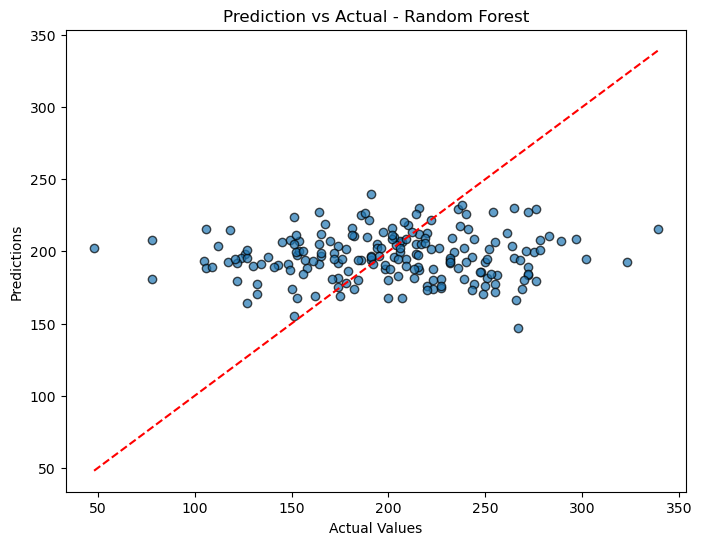

In [59]:
# Visual representation of the scatter plot: predicted vs. actual values

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.7, edgecolor='k')
plt.xlabel("Actual Values")
plt.ylabel("Predictions")
plt.title("Prediction vs Actual - Random Forest")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.show()

### Model Optimization Using RandomizedSearchCV

To improve model performance and tune hyperparameters, `RandomizedSearchCV` was used with 5-fold cross-validation.  
This approach allows for efficiently finding effective parameter combinations without evaluating every possible configuration, saving computational time.

In [60]:
# Define the search space for the Random Forest hyperparameters
param_distributions = {
    'rf__n_estimators': [50, 100, 200, 300],
    'rf__max_depth': [None, 5, 10, 15, 20],
    'rf__max_features': ['sqrt', 'log2'],
    'rf__min_samples_split': [2, 5, 10]
}

# Create the RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_distributions,
    n_iter=20,  # number of random parameter combinations to try
    cv=5,       # 5-fold cross-validation
    scoring='neg_root_mean_squared_error',  # negative RMSE metric
    random_state=42,
    n_jobs=-1   # use all available cores for speed
)

# Run the search on the training data
random_search.fit(X_train, y_train.values.ravel())  # .values.ravel() to avoid shape warnings

# Search results
print("🔎 Best hyperparameters found:")
print(random_search.best_params_)

print("\n✅ Best RMSE (negative, cross-validation):")
print(random_search.best_score_)

# Final evaluation with the best model found
best_model = random_search.best_estimator_

y_pred = best_model.predict(X_test)

from sklearn.metrics import mean_squared_error, r2_score
print("\n📊 Evaluation on test set:")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))


🔎 Best hyperparameters found:
{'rf__n_estimators': 200, 'rf__min_samples_split': 2, 'rf__max_features': 'sqrt', 'rf__max_depth': 5}

✅ Best RMSE (negative, cross-validation):
-50.274263243854435

📊 Evaluation on test set:
RMSE: 50.664355900646086
R2: -0.01567347758773474


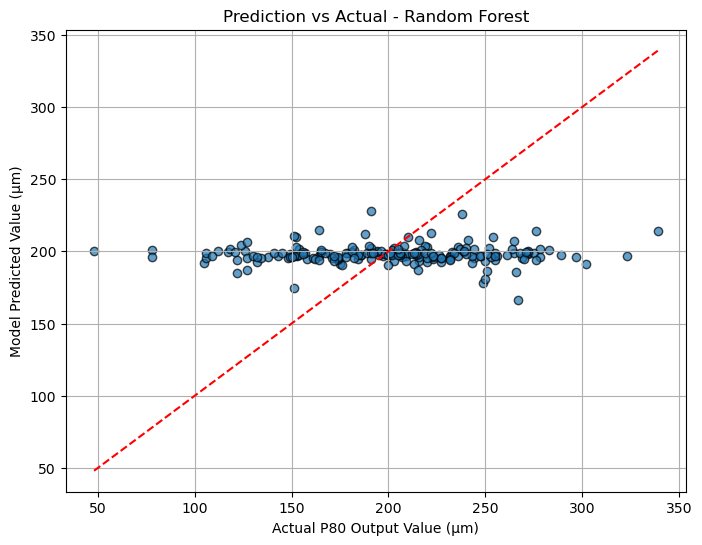

In [61]:
# Scatter plot: actual vs predicted values
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.7, edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # ideal diagonal line
plt.xlabel("Actual P80 Output Value (µm)")
plt.ylabel("Model Predicted Value (µm)")
plt.title("Prediction vs Actual - Random Forest")
plt.grid(True)
plt.show()

Despite applying hyperparameter tuning with `RandomizedSearchCV`, the model did not significantly improve its predictive capability. The RMSE remains high, and the R² stays close to zero or even negative. This is consistent with the fact that the data were artificially generated without real relationships between variables, serving solely to demonstrate technical skills in data science applied to mining.

The use of `RandomizedSearchCV` enabled:

- Application of cross-validation to enhance model robustness.  
- Identification of optimal hyperparameter combinations.  
- Demonstration of advanced understanding in modeling and tuning within industrial contexts.


**Model Conclusion:**  
The results show poor model performance, indicating that it is not capturing significant patterns in the data. This aligns with the earlier exploratory analysis, where no relevant correlations were detected among variables. It is important to note that the data were artificially generated for technical demonstration purposes; therefore, realistic predictive performance is not expected.  

> Nevertheless, the exercise demonstrates competencies in data handling, preprocessing, pipeline usage, categorical encoding, model training, and performance evaluation.

# 5. Overall Project Conclusion

A comprehensive analysis was carried out on a dataset artificially generated by artificial intelligence, aiming to demonstrate technical skills in data cleaning, analysis, visualization, and modeling applied to the comminution process in mineral processing.

From the development of the project, the following conclusions are drawn:

- Proficiency was demonstrated in the use of analytical tools such as `pandas`, `numpy`, `matplotlib`, `seaborn`, and `scikit-learn`, applied coherently within a professional workflow.
- Technical knowledge of the comminution process, a key stage in mineral treatment for the extraction of valuable elements, was evidenced.
- The dataset contained 20 null values that were properly treated, as well as 10 outliers in solids percentage and 10 in output P80. Given the simulated nature of the data, these were removed to facilitate clean analysis.
- As expected from its artificial nature, the dataset showed no significant correlations among most variables.
- One of the few observed relationships was between throughput (tons per hour) and energy consumption per ton, showing an inverse relationship: higher throughput corresponds to lower specific energy consumption.
- For **Mixed-type** minerals, better size reduction (lower output P80) was observed when operating with a solids percentage between 66% and 70%. It is recommended to evaluate the balance between water consumption and recovery to define this operational parameter.
- Also for Mixed minerals, higher energy consumption and increased P80 were detected across the three shifts analyzed, possibly indicating the presence of harder mineral than expected. Operational parameters should be reviewed in this context to optimize performance.
- Finally, the Random Forest predictive model failed to capture useful patterns, yielding poor performance metrics. This aligns with the fact that the data were generated without real relationships, thus not allowing the model to learn.

This project constitutes a practical demonstration of data science skills applied to the mining and metallurgical field, effectively integrating technical knowledge and analytical tools.
